# Liver MRI Student Workshop

Welcome to this hands-on teaching notebook.

In this session, you will work like an imaging researcher. You will inspect the dataset, load MRI slices, visualize liver masks, perform simple quality control, compute an approximate PDFF map, and compare slice-level and case-level measurements.

This notebook is intentionally designed for learning. Each section contains:

- a short explanation of the goal
- a code example
- one or more `TODO` items for you to complete

You do not need to be an expert programmer. Move slowly, read the comments, and run the notebook from top to bottom.

## Learning Goals

By the end of this workshop, you should be able to:

- explain how the teaching dataset is organized
- read DICOM images and basic MRI metadata
- visualize a slice together with a liver mask
- inspect masks across slices for quality control
- compute an approximate PDFF map for dual-echo T1 data
- export a mask and apply it to an image
- compare per-slice PDFF with case-level PDFF summaries

Research mindset: do not only ask whether code runs. Ask whether the output makes anatomical and scientific sense.

## Before You Start: Choose the Correct Data Folder

This repository contains two MRI data locations:

- `data/sample_data/`: a small sample used to verify that your Python environment works
- `data/CHAOS_Train_Sets/Train_Sets/MR/`: the real CHAOS MRI training data for the workshop

Recommended workflow:

1. Start with `sample_data` and confirm that the notebook runs
2. After that, change the active data path to the full CHAOS MRI folder

You will make that path change in the next code cell. That is an intentional part of the exercise.

In [1]:
%matplotlib widget

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import pydicom
from IPython.display import display

plt.style.use('default')
plt.rcParams['figure.figsize'] = (7, 6)
plt.rcParams['image.cmap'] = 'gray'

# Locate the project root. This notebook lives in notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / 'app').exists() and (PROJECT_ROOT / 'notebooks').exists():
    pass
elif not (PROJECT_ROOT / 'app').exists():
    raise RuntimeError('Please start Jupyter from the repository root or open the notebook from inside the repository.')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from app.core.store import DatasetStore, organ_value_from_key
from app.core.imaging import read_dicom_pixels, window_image, approximate_pdff, summarize_pdff, load_label_mask
from app.core.notebook_widgets import (
    browse_slices,
    browse_student_masked_slices,
    create_mask_comparison_browser,
    create_student_segmentation_widget,
    export_student_masks,
    make_mask_cmap,
    preload_slice_frames,
    show_mri_and_mask,
    student_evaluation_table,
)

SAMPLE_DATA_DIR = PROJECT_ROOT / 'data' / 'sample_data'
CHAOS_MR_DATA_DIR = PROJECT_ROOT / 'data' / 'CHAOS_Train_Sets' / 'Train_Sets' / 'MR'

# TODO:
# First, keep this as SAMPLE_DATA_DIR to verify that your environment works.
# For the real hands-on session, change it to CHAOS_MR_DATA_DIR.
ACTIVE_DATA_DIR = SAMPLE_DATA_DIR

OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'notebook_exports'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not ACTIVE_DATA_DIR.exists():
    raise FileNotFoundError(f'Data folder not found: {ACTIVE_DATA_DIR}')

store = DatasetStore(ACTIVE_DATA_DIR)
cases = store.list_cases()

print(f'Project root: {PROJECT_ROOT}')
print(f'Sample data path: {SAMPLE_DATA_DIR}')
print(f'CHAOS MRI path: {CHAOS_MR_DATA_DIR}')
print(f'Active data path: {ACTIVE_DATA_DIR}')
print(f'Number of indexed patients: {len(cases)}')


Project root: c:\Users\User\Documents\GitHub\OneAim_handson
Sample data path: c:\Users\User\Documents\GitHub\OneAim_handson\data\sample_data
CHAOS MRI path: c:\Users\User\Documents\GitHub\OneAim_handson\data\CHAOS_Train_Sets\Train_Sets\MR
Active data path: c:\Users\User\Documents\GitHub\OneAim_handson\data\sample_data
Number of indexed patients: 1


## Step 1: Explore the Dataset Structure

Before reading MRI images, we need to understand how the repository is organized.

Your task in this section:

- list the available patients
- see how many sequences each patient has
- identify whether a sequence supports PDFF

This is a common first step in research: build a quick overview before doing detailed analysis.

In [2]:
# TODO:
# 1. Convert `cases` into a pandas DataFrame.
# 2. Include one row per patient-sequence pair.
# 3. Show the patient ID, sequence name, slice count, and whether PDFF is supported.
# Hint: loop through `cases`, then through each item's `sequences`.

rows = []
for case in cases:
    for sequence in case['sequences']:
        rows.append({
            'patient_id': case['patientId'],
            'sequence': sequence['name'],
            'slice_count': sequence['sliceCount'],
            'supports_pdff': sequence['supportsPdff'],
        })

overview_df = pd.DataFrame(rows).sort_values(['patient_id', 'sequence']).reset_index(drop=True)
overview_df

,patient_id,sequence,slice_count,supports_pdff
0,Sample,T1DUAL,35,True
1,Sample,T2SPIR,36,False


## Step 2: Choose a Case for Hands-On Work

A good teaching case should have paired in-phase and out-phase images so we can later compute an approximate PDFF map.

In the code below, choose one patient and one sequence.

Recommendation:

- pick a `T1DUAL` sequence if you want to work with PDFF
- pick a `T2SPIR` sequence if you want to focus first on anatomy and masks

In [3]:
# TODO:
# Change these values if you want to explore a different case.
# Tip: choose a sequence with supports_pdff == True if possible.

PATIENT_ID = 'Sample'
SEQUENCE_NAME = 'T1DUAL'
ORGAN_KEY = 'liver'

case_detail = store.get_case_detail(PATIENT_ID, SEQUENCE_NAME)
case_detail

{'patientId': 'Sample',
 'sequence': 'T1DUAL',
 'sliceCount': 35,
 'supportsPdff': True,
 'slices': [{'index': 0, 'label': 'IMG-0004-00002'},
  {'index': 1, 'label': 'IMG-0004-00004'},
  {'index': 2, 'label': 'IMG-0004-00006'},
  {'index': 3, 'label': 'IMG-0004-00008'},
  {'index': 4, 'label': 'IMG-0004-00010'},
  {'index': 5, 'label': 'IMG-0004-00012'},
  {'index': 6, 'label': 'IMG-0004-00014'},
  {'index': 7, 'label': 'IMG-0004-00016'},
  {'index': 8, 'label': 'IMG-0004-00018'},
  {'index': 9, 'label': 'IMG-0004-00020'},
  {'index': 10, 'label': 'IMG-0004-00022'},
  {'index': 11, 'label': 'IMG-0004-00024'},
  {'index': 12, 'label': 'IMG-0004-00026'},
  {'index': 13, 'label': 'IMG-0004-00028'},
  {'index': 14, 'label': 'IMG-0004-00030'},
  {'index': 15, 'label': 'IMG-0004-00032'},
  {'index': 16, 'label': 'IMG-0004-00034'},
  {'index': 17, 'label': 'IMG-0004-00036'},
  {'index': 18, 'label': 'IMG-0004-00038'},
  {'index': 19, 'label': 'IMG-0004-00040'},
  {'index': 20, 'label': 'IMG-0

## Step 3: Inspect the Folder and Slice List

Now we move from the high-level table to one concrete case.

Questions to think about:

- How many slices does this sequence contain?
- What does one slice filename look like?
- Does this case support PDFF?

In [4]:
# TODO:
# Print the number of slices and the first five slice labels.
# Hint: use case_detail['sliceCount'] and case_detail['slices'].

print('Slice count:', case_detail['sliceCount'])
print('Supports PDFF:', case_detail['supportsPdff'])
print('First five slice labels:')
for item in case_detail['slices'][:5]:
    print('  ', item['index'], item['label'])

Slice count: 35
Supports PDFF: True
First five slice labels:
   0 IMG-0004-00002
   1 IMG-0004-00004
   2 IMG-0004-00006
   3 IMG-0004-00008
   4 IMG-0004-00010


## Step 4: Read One DICOM Slice and Its Metadata

DICOM files contain both image pixels and metadata.

In this step, you will inspect one slice and extract a few important metadata fields:

- image shape
- pixel spacing
- slice thickness
- series description if available

These values matter because MRI analysis is not only about image intensity. Physical spacing also matters.

In [5]:
slice_index = case_detail['sliceCount'] // 2
sequence = store._get_sequence(PATIENT_ID, SEQUENCE_NAME)
record = sequence['slices'][slice_index]
ds = pydicom.dcmread(record.dicom_path)
pixels = read_dicom_pixels(ds)
display_image = window_image(ds)

# TODO:
# Read and print the metadata below.
# Hint: PixelSpacing is often a list-like object in DICOM.

print('Selected slice index:', slice_index)
print('File:', record.dicom_path.name)
print('Pixel array shape:', pixels.shape)
print('Pixel spacing:', getattr(ds, 'PixelSpacing', 'not available'))
print('Slice thickness:', getattr(ds, 'SliceThickness', 'not available'))
print('Series description:', getattr(ds, 'SeriesDescription', 'not available'))

Selected slice index: 17
File: IMG-0004-00036.dcm
Pixel array shape: (256, 256)
Pixel spacing: [1.89453125, 1.89453125]
Slice thickness: 5
Series description: 


## Step 5: Visualize the MRI Slice and the Liver Mask

Ground-truth masks are stored as PNG files in the `Ground/` folder.

Here you will:

- load the liver mask for the same slice
- show the MRI image alone
- show the MRI image with the liver mask overlay

This is a core skill in imaging research: always inspect the image and annotation together.

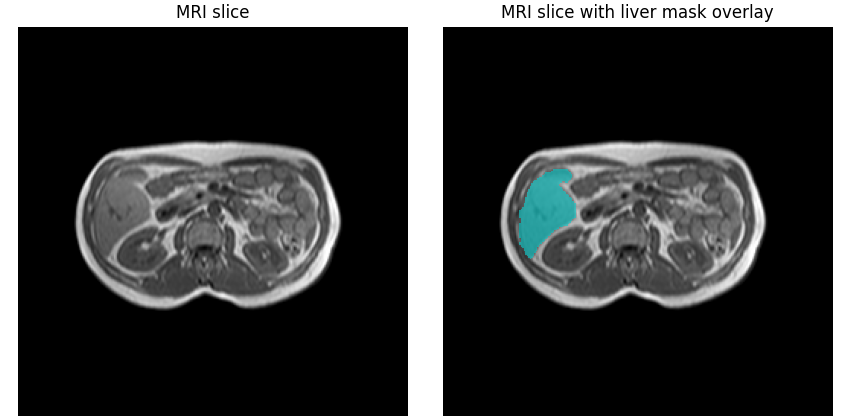

Mask area in pixels: 1345


In [6]:
organ_value = organ_value_from_key(ORGAN_KEY)
gt_mask = load_label_mask(record.gt_path, organ_value)

# A transparent cyan overlay makes the mask easier to see.
mask_cmap = make_mask_cmap((0.0, 0.85, 0.85), alpha=0.55)

# TODO:
# Read the plotting code and explain to a classmate what each panel shows.

show_mri_and_mask(display_image, gt_mask, mask_cmap)

print('Mask area in pixels:', int(gt_mask.sum()))


## Step 6: Perform a Simple QC Check Across Slices

Quality control means checking whether the data and annotations behave as expected.

A simple first QC idea is to measure the liver mask area on every slice.

Questions:

- On which slice is the liver largest?
- Are there slices with no liver mask at all?
- Does the pattern across slices look smooth or suspicious?

,slice_index,slice_label,mask_area
0,0,IMG-0004-00002,0
1,1,IMG-0004-00004,0
2,2,IMG-0004-00006,0
3,3,IMG-0004-00008,0
4,4,IMG-0004-00010,0


Largest liver mask is on slice: 32
Largest liver mask area: 6114


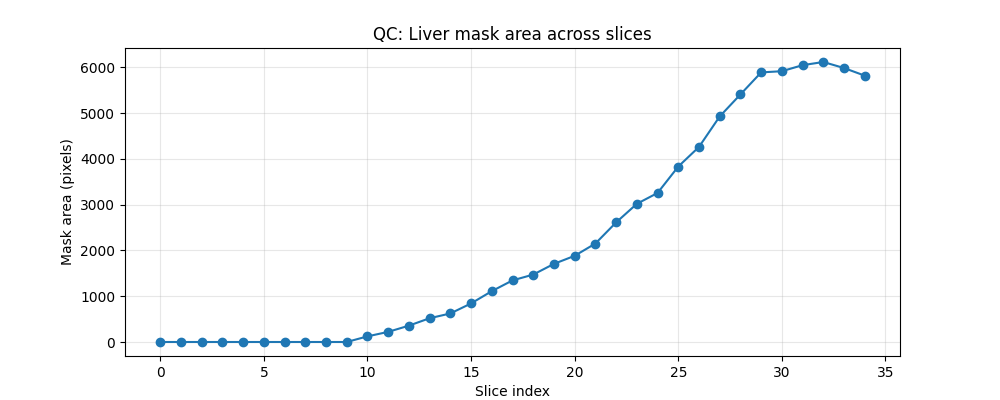

In [7]:
# TODO:
# Loop over all slices in the chosen sequence.
# For each slice, load the liver mask and record the mask area.

slice_rows = []
for idx, slice_record in enumerate(sequence['slices']):
    mask = load_label_mask(slice_record.gt_path, organ_value)
    slice_rows.append({
        'slice_index': idx,
        'slice_label': slice_record.basename,
        'mask_area': int(mask.sum()),
    })

qc_df = pd.DataFrame(slice_rows)
largest_slice = qc_df.loc[qc_df['mask_area'].idxmax()]

display(qc_df.head())
print('Largest liver mask is on slice:', int(largest_slice['slice_index']))
print('Largest liver mask area:', int(largest_slice['mask_area']))

plt.figure(figsize=(10, 4))
plt.plot(qc_df['slice_index'], qc_df['mask_area'], marker='o')
plt.xlabel('Slice index')
plt.ylabel('Mask area (pixels)')
plt.title('QC: Liver mask area across slices')
plt.grid(alpha=0.3)
plt.show()

## Step 7: Browse Different Slices

Looking at only one slice is rarely enough. We also want to browse the volume.

Use the slider below to inspect how anatomy and the liver mask change through the stack.

As you scroll, pay attention to:

- where the liver first appears
- where the liver is largest
- where the liver disappears again

In [8]:
slice_images, slice_masks, slice_labels = preload_slice_frames(sequence['slices'], organ_value)

slice_browser = browse_slices(
    slice_images,
    slice_masks,
    slice_labels,
    mask_cmap,
    initial_index=slice_index,
)
display(slice_browser)


## Step 8: Compute an Approximate PDFF Map

For dual-echo T1 data, we can combine in-phase and out-phase images to estimate an approximate PDFF map.

Important: this notebook uses a simplified teaching approximation. It is useful for learning, but it is not a clinical PDFF pipeline.

In this section, you will:

- check whether the selected slice has a matched out-phase image
- compute the approximate PDFF map
- visualize the PDFF map next to the MRI slice

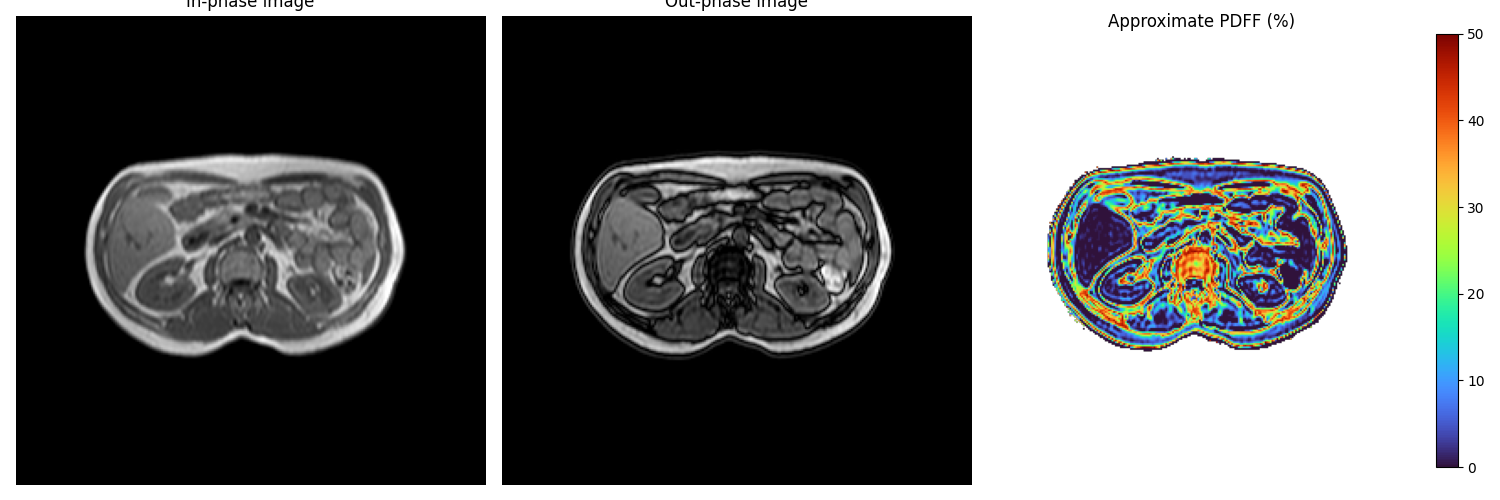

In [9]:
if record.out_phase_path is None:
    raise ValueError('This slice does not have a matched out-phase image. Choose a dual-echo T1 case.')

out_ds = pydicom.dcmread(record.out_phase_path)
in_pixels = read_dicom_pixels(ds)
out_pixels = read_dicom_pixels(out_ds)

# TODO:
# Compute the approximate PDFF map using the helper function from app.core.imaging.
# Then visualize it. Think about why some pixels may become NaN.

pdff_map = approximate_pdff(in_pixels, out_pixels)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(window_image(ds), cmap='gray')
axes[0].set_title('In-phase image')
axes[0].axis('off')

axes[1].imshow(window_image(out_ds), cmap='gray')
axes[1].set_title('Out-phase image')
axes[1].axis('off')

im = axes[2].imshow(pdff_map * 100, cmap='turbo', vmin=0, vmax=50)
axes[2].set_title('Approximate PDFF (%)')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## Step 9: Measure Liver PDFF on One Slice

Now we move from visualization to measurement.

We will use the liver mask to keep only pixels inside the liver, then summarize the PDFF values.

Think carefully about the difference between:

- the image itself
- the mask
- the values inside the mask

Ground-truth liver PDFF stats for this slice:
{'mean': 7.01, 'median': 2.43, 'voxelCount': 661}


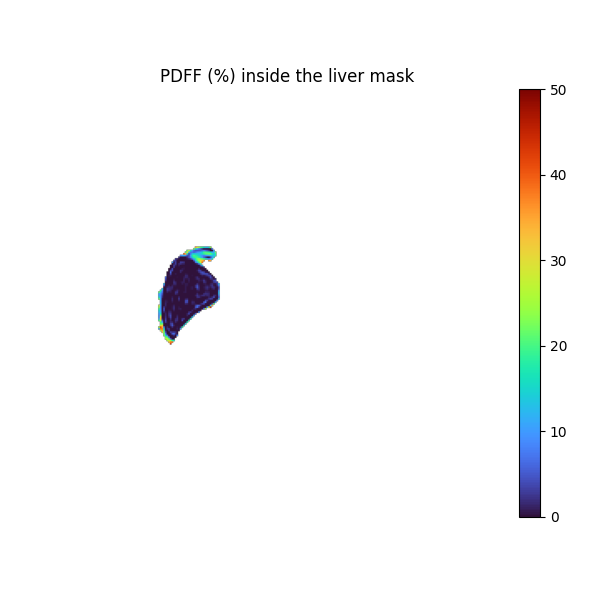

In [10]:
# TODO:
# Use summarize_pdff to compute statistics inside the liver mask.
# Then create a masked PDFF image that keeps only liver pixels.

gt_pdff_stats = summarize_pdff(pdff_map, gt_mask)
masked_pdff = np.where(gt_mask > 0, pdff_map * 100, np.nan)

print('Ground-truth liver PDFF stats for this slice:')
print(gt_pdff_stats)

plt.figure(figsize=(6, 6))
plt.imshow(masked_pdff, cmap='turbo', vmin=0, vmax=50)
plt.title('PDFF (%) inside the liver mask')
plt.axis('off')
plt.colorbar(fraction=0.046, pad=0.04)
plt.show()

## Step 10: Draw Student Segmentations With the Mouse

In this step, you will create one or more student segmentations directly inside the notebook.

Use the slice slider or the `Previous` / `Next` buttons to choose a slice, then left-click around the liver boundary on the image.

Instructions:

1. Choose a slice with the slider or navigation buttons
2. Left-click points around the liver boundary
3. Click `Undo Point` if you make a mistake on the current slice
4. Click `Reset` to clear only the current slice
5. Click `Close Polygon` to connect the last point to the first point
6. Click `Generate Mask` to save the mask for that slice and fill the selected area
7. Move to another slice and repeat if you want a multi-slice student segmentation

After `Generate Mask`, the later cells will use all saved student masks for export, visualization, Dice/IoU comparison, PDFF analysis, and slice-by-slice comparison.

If the image is not clickable, make sure `ipympl` is installed, restart the notebook kernel, and run from the top again.


In [11]:
# Interactive student segmentation.
# TODO:
# 1. Choose a slice with the slider.
# 2. Click around the liver boundary on the image.
# 3. Close the polygon and generate the mask.
# 4. Repeat on other slices if you want a multi-slice 3D result.

segmentation_widget, segmentation_state = create_student_segmentation_widget(
    slice_images,
    slice_masks,
    slice_labels,
    initial_index=slice_index,
    namespace=globals(),
    output_dir=OUTPUT_DIR,
    patient_id=PATIENT_ID,
    sequence_name=SEQUENCE_NAME,
)
display(segmentation_widget)


## Step 11: Export the Student Masks

Exporting intermediate results is good research practice.

Here you will save every generated student mask as a PNG file. This makes it easier to inspect results, share outputs, or compare versions later.


In [18]:
# TODO:
# Save every generated student mask as an 8-bit PNG.
# Convention: foreground = 255, background = 0.

export_paths = export_student_masks(student_masks, OUTPUT_DIR, PATIENT_ID, SEQUENCE_NAME)

print('Saved masks:')
for path in export_paths:
    print(path)


Saved masks:
c:\Users\User\Documents\GitHub\OneAim_handson\outputs\notebook_exports\Sample_T1DUAL_slice015_student_mask.png
c:\Users\User\Documents\GitHub\OneAim_handson\outputs\notebook_exports\Sample_T1DUAL_slice016_student_mask.png
c:\Users\User\Documents\GitHub\OneAim_handson\outputs\notebook_exports\Sample_T1DUAL_slice017_student_mask.png


## Step 12: Apply the Mask to the MRI Image

A mask can be used to isolate the region of interest.

This is useful when you only want to analyze pixels inside the liver and ignore everything else.

In [19]:
# TODO:
# Browse each generated student mask and inspect the isolated MRI pixels.

student_mask_browser = browse_student_masked_slices(
    slice_images,
    student_masks,
    slice_labels,
)
display(student_mask_browser)


## Step 13: Compare Dice/IoU Across Student-Masked Slices

Small segmentation differences can change quantitative measurements.

This is why segmentation quality matters in quantitative MRI research.

Now compare the saved student masks with the expert ground-truth masks for every slice you segmented.


In [20]:
# TODO:
# Review the Dice and IoU scores for each slice with a generated student mask.

comparison_df = pd.DataFrame(student_evaluation_table(student_evaluations))
comparison_df


,slice_index,dice,iou,student_area,ground_truth_area
0,15,0.8833,0.7910,675,842
1,16,0.8894,0.8009,952,1110
2,17,0.8838,0.7917,1124,1345


## Step 14: Slice-Wise PDFF Versus Case-Wise Average PDFF

A very important research lesson is that one slice does not always represent the whole case.

In this step, you will compute PDFF statistics for every slice in the case and compare them with an overall mean.

Key concept:

- `mean of slice means` gives every slice equal weight
- `global mean over all masked pixels` gives larger liver slices more influence

These two numbers can be different.

Mean of slice means: 7.24%
Global mean over all liver pixels: 6.30%


,slice_index,mean_pdff_percent,median_pdff_percent,voxel_count
0,10,18.41,16.40,88
1,11,11.82,6.27,126
2,12,8.94,3.64,212
3,13,9.49,3.64,283
4,14,5.71,2.20,320


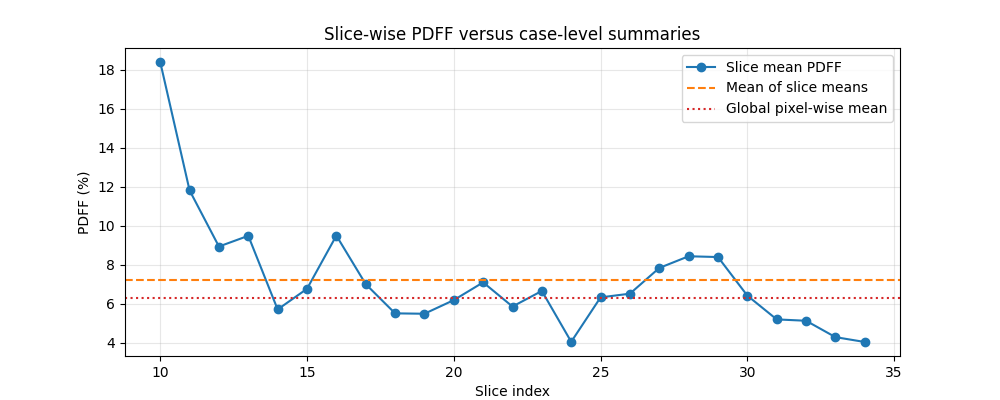

In [21]:
per_slice_rows = []
all_masked_values = []

for idx, slice_record in enumerate(sequence['slices']):
    if slice_record.out_phase_path is None:
        continue

    in_ds_i = pydicom.dcmread(slice_record.dicom_path)
    out_ds_i = pydicom.dcmread(slice_record.out_phase_path)
    in_pixels_i = read_dicom_pixels(in_ds_i)
    out_pixels_i = read_dicom_pixels(out_ds_i)
    pdff_i = approximate_pdff(in_pixels_i, out_pixels_i)
    mask_i = load_label_mask(slice_record.gt_path, organ_value)
    stats_i = summarize_pdff(pdff_i, mask_i)

    if stats_i is None:
        continue

    values_i = pdff_i[mask_i > 0]
    values_i = values_i[np.isfinite(values_i)]
    values_i = values_i[values_i > 0]
    if values_i.size > 0:
        all_masked_values.append(values_i)

    per_slice_rows.append({
        'slice_index': idx,
        'mean_pdff_percent': stats_i['mean'],
        'median_pdff_percent': stats_i['median'],
        'voxel_count': stats_i['voxelCount'],
    })

per_slice_df = pd.DataFrame(per_slice_rows)

# TODO:
# Compare these two summary strategies:
# 1. average of per-slice means
# 2. global mean over all masked pixels from all slices

mean_of_slice_means = per_slice_df['mean_pdff_percent'].mean()
global_mean = np.concatenate(all_masked_values).mean() * 100 if all_masked_values else np.nan

print(f'Mean of slice means: {mean_of_slice_means:.2f}%')
print(f'Global mean over all liver pixels: {global_mean:.2f}%')

display(per_slice_df.head())

plt.figure(figsize=(10, 4))
plt.plot(per_slice_df['slice_index'], per_slice_df['mean_pdff_percent'], marker='o', label='Slice mean PDFF')
plt.axhline(mean_of_slice_means, color='tab:orange', linestyle='--', label='Mean of slice means')
plt.axhline(global_mean, color='tab:red', linestyle=':', label='Global pixel-wise mean')
plt.xlabel('Slice index')
plt.ylabel('PDFF (%)')
plt.title('Slice-wise PDFF versus case-level summaries')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Step 15: Slice-by-Slice Student and GT Comparison

Use the slider below to inspect each slice where you generated a student mask.

The overlay uses three colors:

- green: overlap between your mask and the GT mask
- amber: area included only by your mask
- red: GT area missed by your mask

This view is lighter than the 3D view and makes it easier to see exactly where a slice needs improvement.


In [22]:
student_gt_comparison_browser = create_mask_comparison_browser(
    slice_images,
    student_masks,
    slice_masks,
    slice_labels,
)
display(student_gt_comparison_browser)


## Step 16: Reflection Questions

Discuss these questions with your group or write short answers below:

1. Why is it important to inspect the folder structure before analysis?
2. Why should we always visualize the image together with the mask?
3. Why might a student mask produce a different PDFF estimate from the ground-truth mask?
4. Why can the mean of slice means differ from the global pixel-wise mean?
5. If you were designing the next version of this project, what would you improve?

These are the kinds of questions that turn coding into scientific reasoning.


In [17]:
# Optional free-response cell.
# Write your notes here.

notes = {
    'question_1': '',
    'question_2': '',
    'question_3': '',
    'question_4': '',
    'question_5': '',
}

notes

{'question_1': '',
 'question_2': '',
 'question_3': '',
 'question_4': '',
 'question_5': ''}